In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load manifold (scores already computed in 02); report gene recovery
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
for src, lab in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0])

Gast: 78/81 genes present
pSom: 94/98 genes present
Crest: 102/104 genes present
cells: 4985


In [ ]:
# Gate 2 test — module geography + developmental order along pseudotime.
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm', 'pSom_sm'), ('Crest_sm', 'Gast_sm'), ('Crest_sm', 'pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0, 1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t - t.min())/(t.max() - t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm', 'pSom_sm', 'Crest_sm']:
    rho, _ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('global module means (raw score_genes):',
      adata.obs[['Gast', 'pSom', 'Crest']].mean().round(3).to_dict())
print()
print('Gate 2: Gast/pSom co-vary (r=+0.60) and BOTH oppose Crest (-0.89/-0.76);')
print('        single developmental axis, Crest an inverse terminal gradient -> GO (non-branching).')
print('Gate 3: no bifurcation -> NA.')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.60
  Crest_sm vs Gast_sm: r = -0.89
  Crest_sm vs pSom_sm: r = -0.76
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.872
  pSom_sm: rho = -0.379
  Crest_sm: rho = +0.756
neural-crest-high decile mean pseudotime = 0.97 (terminal if ~1)
global module means (raw score_genes): {'Gast': -0.068, 'pSom': 0.211, 'Crest': -0.15}

Gate 2: Gast/pSom co-vary (r=+0.60) and BOTH oppose Crest (-0.89/-0.76);
        single developmental axis, Crest an inverse terminal gradient -> GO (non-branching).
Gate 3: no bifurcation -> NA.


saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


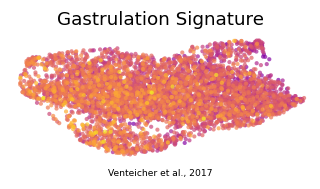

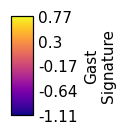

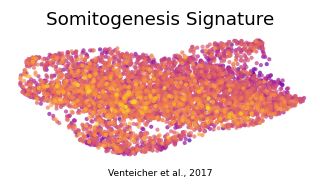

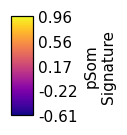

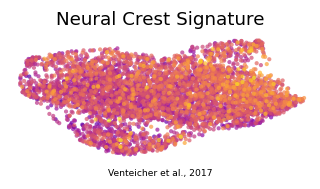

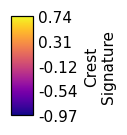

In [ ]:
# deliverables: raw-score signature UMAPs (house 3.5,1.5) + external colorbars.
# raw score_genes shown (not smoothed) per the binding deliverable rule.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
titles = {'Gast': 'Gastrulation Signature', 'pSom': 'Somitogenesis Signature', 'Crest': 'Neural Crest Signature'}
for m in ['Gast', 'pSom', 'Crest']:
    fig, ax = plt.subplots(figsize=(3.5, 1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.12, 'Venteicher et al., 2017', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66, 1)); cax = fcb.add_axes([.35, .05, .3, .9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [ ]:
# save signatures h5ad
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (4985, 21911)
